In [ ]:
'''import sys
import warnings
from collections import namedtuple
from functools import partial
from pathlib import Path

# course_helpers.py sits in this folder, next to the notebook.
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style='whitegrid')
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.preprocessing import (
    MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler,
)

# course_helpers.py is the course toolbox: one file, kept beside every
# notebook, holding what is the same every week. It contains no machine
# learning, only the two plot colours and CleaningLog, a small recorder for the
# decisions made below. It is short; open it.

#from course_helpers import PLOT_BLUE, PLOT_ORANGE, CleaningLog

#RANDOM_STATE = 42
#np.random.seed(RANDOM_STATE)  # For reproducibility
#FIGSIZE = (10, 6)

# One warning class is silenced here, on purpose. Read the next cell before
# deciding whether that is ever a reasonable thing to do.

#warnings.filterwarnings('ignore', category=ConvergenceWarning)'''

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


#RANDOM_STATE = 42
#np.random.seed(RANDOM_STATE)  # For reproducibility
#FIGSIZE = (10, 6)

In [2]:
train_raw = pd.read_csv('../data/train.csv', index_col='ID')

print(f'Train dataset dimensions: {train_raw.shape[0]} rows x {train_raw.shape[1]} feature columns, indexed by ID')
train_raw

Train dataset dimensions: 6534 rows x 38 feature columns, indexed by ID


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.00,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.00,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.00,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.00,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.00,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10007670,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,1,16.0,196.0,5.0,5548.20,1109.640000,1213.808411,254.47,3041.05,45.000000,22.700954,2.0,562.31,3.0,3603.36,4.0,3962.95,5.0,5548.20,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,-1.579719
10007671,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,0,367.0,367.0,1.0,625.91,625.910000,NaN,625.91,625.91,NaN,NaN,0.0,0.00,0.0,0.00,0.0,0.00,0.0,0.00,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,-0.576883
10007672,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,1,77.0,2331.0,78.0,102675.07,1316.347051,1295.241815,3.20,6144.21,29.272727,29.017525,0.0,0.00,2.0,2214.29,7.0,14817.28,13.0,27824.52,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,0.528377


In [3]:
print('Train Data Types:')
print(train_raw.dtypes)

Train Data Types:
Total a Pagar                     float64
Total Bruto                       float64
Total Liquido                     float64
Total Imp_                        float64
Total Portes                      float64
Total Desc_ Global                float64
Total Desc_ Linha                 float64
Custo                             float64
N_ Detalhes                       float64
invoice_count_current_purchase    float64
repeat_purchase_90d                 int64
days_since_previous_purchase      float64
customer_tenure_days              float64
prior_purchase_count              float64
prior_total_spend                 float64
prior_mean_purchase_value         float64
prior_std_purchase_value          float64
prior_min_purchase_value          float64
prior_max_purchase_value          float64
prior_mean_gap_days               float64
prior_std_gap_days                float64
purchase_count_30d                float64
spend_30d                         float64
purchase_count_9

## Data overview
The table below groups the features of `train.csv` by the kind of information they carry and type of variable. The target, `repeat_purchase_90d`, and the identifiers are listed separately because they are not used as predictors.

The type of variable is decided by what each column measures and not by its pandas data type, as shown above. Several count features are stored as `float` even though they are discrete.
|Group|Features|Info|Type of variable|
|---|---|---|---|
|Identifiers|`ID`, `customer_id`|Unique `ID` is the index we have chosen for the dataset; `customer_id` is the join key between `train`/`test` datasets and the `clientes` dataset|Identifier|
|**Target**|`repeat_purchase_90d`|1 if the customer makes another purchase within 90 days, 0 if not|Binary Categorical (Boolean)|
|Purchase amounts|`Total a Pagar`, `Total Bruto`, `Total Liquido`, `Total Imp_`, `Total Portes`, `Total Desc_ Global`, `Total Desc_ Linha`, `Custo`|Amount payable; Gross total; Net total; Tax; Shipping costs; Line discount; Global discount; Cost|Continuous Numeric|
|Purchase details|`N_ Detalhes`, `invoice_count_current_purchase`|Number of detail lines; number of invoices in the occasion|Discrete Numeric|
|Commercial and logistics attributes of the purchase|`payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series`|Self-explanatory from the columns names|Nominal Categorical|
|Past purchases values statistics|`prior_mean_purchase_value`, `prior_std_purchase_value`, `prior_min_purchase_value`, `prior_max_purchase_value`|Mean, standard deviation, minimium and maximum of past purchases spends|Continuous Numeric|
|Past purchases by time period|`prior_purchase_count`, `purchase_count_30d`, `purchase_count_90d`, `purchase_count_180d`, `purchase_count_365d`|Count of all past purchases and in the previous 30, 90, 180, 365 days|Discrete Numeric|
|Spend by time period|`prior_total_spend`, `spend_30d`, `spend_90d`, `spend_180d`, `spend_365d`|Spend across all past purchases and in the previous 30, 90, 180, 365 days|Continuous Numeric|
|Customer timeline|`days_since_previous_purchase`, `customer_tenure_days`|Self-explanatory from the columns names|Discrete Numeric|
|Past purchases values statistics|`prior_mean_gap_days`, `prior_std_gap_days`|Mean and standard deviation of the days between past purchases|Continuous Numeric|
|Date|`purchase_date`|Self-explanatory from the column name|Date|
|Unknown|`random_noise`|Appears to be a randomly generated numeric feature rather than a meaningful customer or purchase measure|Continuous Numeric|

In [4]:
identifier=['customer_id']
target=['repeat_purchase_90d']
discrete=['N_ Detalhes', 'invoice_count_current_purchase', 'prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d', 'days_since_previous_purchase', 'customer_tenure_days']
date=['purchase_date']
categorical=[c for c in train_raw.columns if c not in identifier+target+discrete+date and pd.api.types.is_string_dtype(train_raw[c])]
continuous=[c for c in train_raw.columns if c not in identifier+target+discrete+date+categorical]
numeric=discrete+continuous

len(numeric)+len(categorical)+len(date)+len(target)+len(identifier)==train_raw.shape[1]

True

In [5]:
low_cardinality = [c for c in numeric if train_raw[c].nunique() <= 13] #test if the low cardinality numeric features are actually labels
low_cardinality
for c in low_cardinality:
    print(train_raw[c].value_counts())

invoice_count_current_purchase
1.0    6116
2.0     312
4.0      21
3.0      14
5.0       6
Name: count, dtype: int64
purchase_count_30d
0.0     4342
1.0     1334
2.0      394
3.0      172
4.0       88
5.0       42
6.0       40
7.0       27
8.0       18
9.0        9
10.0       2
11.0       1
Name: count, dtype: int64


In [6]:
train_raw[numeric].nunique().sort_values()

invoice_count_current_purchase       5
purchase_count_30d                  12
purchase_count_90d                  23
purchase_count_180d                 38
purchase_count_365d                 61
Total Desc_ Global                 109
N_ Detalhes                        171
Total Portes                       215
prior_purchase_count               277
days_since_previous_purchase       495
prior_max_purchase_value          1156
prior_min_purchase_value          1157
spend_30d                         2105
customer_tenure_days              2121
Total Desc_ Linha                 3519
spend_90d                         3523
prior_mean_gap_days               3874
prior_std_gap_days                4911
spend_180d                        5020
Total Imp_                        5406
prior_std_purchase_value          5420
spend_365d                        5434
prior_mean_purchase_value         5651
Custo                             5736
prior_total_spend                 5862
Total Bruto              

Although these three features have a low cardinality compared with the others, they are still numeric counts

In [59]:
zero_summary = pd.DataFrame({'Zero Count': (train_raw[numeric] == 0).sum(), 'Zero %': ((train_raw[numeric] == 0).sum()/train_raw[numeric].count()*100).round(2)})
zero_summary.sort_values('Zero Count', ascending=False)

,Zero Count,Zero %
Total Desc_ Global,6359,98.30
Total Portes,5416,83.72
spend_30d,4342,67.12
purchase_count_30d,4342,67.12
purchase_count_90d,2889,44.66
spend_90d,2889,44.66
Total Desc_ Linha,2441,37.73
spend_180d,1410,21.80
purchase_count_180d,1410,21.80
purchase_count_365d,843,13.03


In [7]:
n_categories = train_raw[categorical].nunique().sort_values(ascending=False)
n_categories

transport_method    80
payment_type         9
salesperson          9
commercial_zone      5
document_series      3
warehouse            2
dtype: int64

In [8]:
for c in n_categories[n_categories<=10].index:
    print(f'{c:20s} {sorted(train_raw[c].dropna().unique())}\n')

payment_type         ['Maybe Tomorrow Payment 10', 'Maybe Tomorrow Payment 11', 'Maybe Tomorrow Payment 12', 'Maybe Tomorrow Payment 2', 'Maybe Tomorrow Payment 3', 'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 7', 'Maybe Tomorrow Payment 8', 'Maybe Tomorrow Payment 9']

salesperson          ['VLOOKUP Master 1', 'VLOOKUP Master 2', 'VLOOKUP Master 3', 'VLOOKUP Master 4', 'VLOOKUP Master 5', 'VLOOKUP Master 6', 'VLOOKUP Master 7', 'VLOOKUP Master 8', 'VLOOKUP Master 9']

commercial_zone      ['Decorative Dashboard Zone 2', 'Decorative Dashboard Zone 3', 'Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']

document_series      ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']

warehouse            ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']



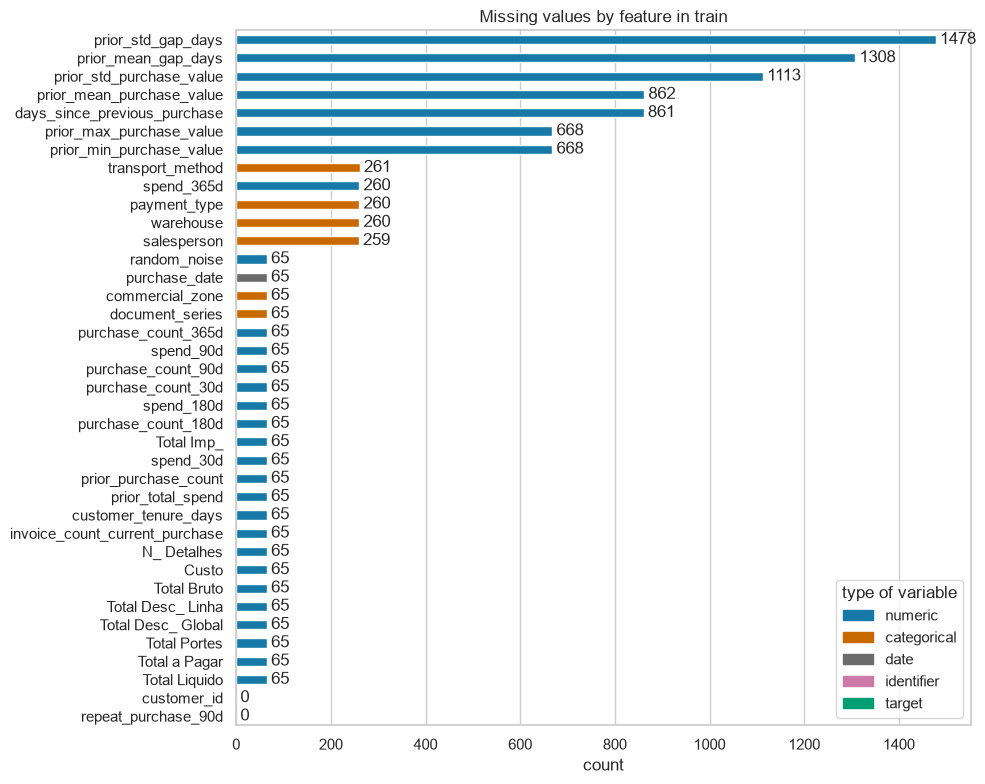

In [9]:
missing = train_raw.isnull().sum().sort_values()

groups = {'numeric': numeric, 'categorical': categorical, 'date': date, 'identifier': identifier, 'target': target}
palette = {'numeric': '#1779A8', 'categorical': '#C96A00', 'date': '#6B6B6B', 'identifier': '#CC79A7', 'target': '#009E73'}

dict_columns = {c: name for name, col in groups.items() for c in col} #a dictionary which specifies, for each column, the type to which it belongs.

colors = [palette[dict_columns[c]] for c in missing.index]
ax = missing.plot(kind='barh', color=colors, figsize=(10, 8))
ax.bar_label(ax.containers[0], padding=3)
ax.grid(axis='y', visible=False)
ax.legend(handles=[Patch(color=c, label=k) for k, c in palette.items()], title='type of variable')
ax.set(xlabel='count', title='Missing values by feature in train')
plt.tight_layout()
plt.show()

In [10]:
rows_with_missing_values = train_raw.isna().any(axis=1)
cells_with_missing_values = train_raw.isna().sum().sum()
print(f'rows with missing values: {rows_with_missing_values.sum()} of {len(train_raw)} ({100*rows_with_missing_values.mean().round(4)}%)')
print(f'cells with missing values (ignoring the index): {cells_with_missing_values} of {train_raw.size} ({(cells_with_missing_values/train_raw.size*100).round(2)}%)')

rows with missing values: 2605 of 6534 (39.87%)
cells with missing values (ignoring the index): 9818 of 248292 (3.95%)


In [11]:
almost_empty_rows = train_raw[numeric+categorical+date].isnull().all(axis=1)
print(f'There are {almost_empty_rows.sum()} almost empty rows, with 36 of 38 features missing. They only store customer_id and repeat_purchase_90d')
train_raw[almost_empty_rows].head()

There are 65 almost empty rows, with 36 of 38 features missing. They only store customer_id and repeat_purchase_90d


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,755628,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,508217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000870,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,427118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
train_raw[numeric+categorical+date].isnull().sum(axis=1).value_counts().sort_index().to_frame('count of rows with missing values').rename_axis('count of missing values')

,count of rows with missing values
count of missing values,
0,3929
1,1287
2,190
3,354
4,100
5,6
7,511
8,86
9,6


In [13]:
duplicated_rows = train_raw.duplicated().sum()
print(f'duplicated rows (surplus): {duplicated_rows}')
same_rows=train_raw.duplicated(keep=False).sum() #keep=False to count every row involved in duplication and not only the surplus
print(f'rows involved in duplications: {same_rows}')

duplicated rows (surplus): 10
rows involved in duplications: 16


All numeric features except `random_noise` are non-negative

In [14]:
non_negative = [c for c in numeric if c != 'random_noise']
negative_summary=pd.DataFrame({'Min': train_raw[non_negative].min(), 'Negative Count': (train_raw[non_negative] < 0).sum(),
                               'Distict Negative Values': (train_raw[train_raw[non_negative] < 0]).nunique()}).sort_values('Negative Count')
negative_summary=negative_summary[negative_summary['Negative Count'] > 0]

negative_summary

,Min,Negative Count,Distict Negative Values
spend_365d,-159115.175535,15.0,15
prior_mean_purchase_value,-2478.658478,16.0,16
days_since_previous_purchase,-4.000000,16.0,1
prior_mean_gap_days,-4.000000,16.0,1


In [15]:
print(f'days_since_previous_purchase negative value: {train_raw.loc[train_raw['days_since_previous_purchase'] < 0, 'days_since_previous_purchase'].values[0]}')
print(f'prior_mean_gap_days: {train_raw.loc[train_raw['prior_mean_gap_days'] < 0, 'prior_mean_gap_days'].values[0]}')

days_since_previous_purchase negative value: -4.0
prior_mean_gap_days: -4.0


These 4 features are calculated based on others: `spend_365d` is calculated as the sum of `Total a Pagar` over a one-year period; `days_since_previous_purchase` is calculated as the difference between the current and the last `purchase_date`; `prior_mean_gap_days` as the mean of `days_since_previous_purchase` from previous dates; and `prior_mean_purchase_value` as `prior_total_spend` divided by `prior_purchase_count`. In both `days_since_previous_purchase` and `prior_mean_gap_days`, all negative values are equal to -4, suggesting that this may be a special code for missing values or a data anomaly. Therefore, applying the absolute value is not justified, and treating these observations as missing values may be more appropriate. For `spend_365d` and `prior_mean_purchase_value`, due to the variability of the negative values, they may have been caused by typing errors involving the minus sign: it is hypothesized that the actual values are the absolute values of the original ones.

$$\text{prior\_mean\_purchase\_value} = \frac{\text{prior\_total\_spend}}{\text{prior\_purchase\_count}}$$

In [16]:
negative_mean_purchase=train_raw[train_raw['prior_mean_purchase_value'] < 0].copy()
negative_mean_purchase['calculated_mean']=(negative_mean_purchase['prior_total_spend']/negative_mean_purchase['prior_purchase_count'])
negative_mean_purchase['abs_check']=np.isclose(negative_mean_purchase['prior_mean_purchase_value'].abs(), negative_mean_purchase['calculated_mean'])

negative_mean_purchase['abs_check'].value_counts()

abs_check
True    16
Name: count, dtype: int64

It appears that in `prior_mean_purchase_value` there was just a typing error involving the minus sign.

$$\text{spend\_365d} = \sum_{\text{last 365 days}}{\text{Total a Pagar}}$$

In [17]:
train_sorted = train_raw.copy()
train_sorted['purchase_date'] = pd.to_datetime(train_sorted['purchase_date'])
train_sorted = train_sorted.dropna(subset=['purchase_date'])
train_sorted = train_sorted.sort_values(['customer_id', 'purchase_date'])

train_sorted['calculated_spend'] = (
    train_sorted.groupby('customer_id')
    .apply(
        lambda g: g.set_index('purchase_date')['Total a Pagar']
        .rolling('365D', closed='left').sum()
    )
    .reset_index(level=0, drop=True)
    .to_numpy()
)

negative_spend = train_sorted[train_sorted['spend_365d'] < 0].copy()

negative_spend['abs_check'] = np.isclose(
    negative_spend['spend_365d'].abs(),
    negative_spend['calculated_spend'],
)

negative_spend['abs_check'].value_counts()

abs_check
True     14
False     1
Name: count, dtype: int64

Among the 15 negative values found in `spend_365d`, 14 match the sum of the customer's previous purchases within the preceding 365 days after applying the absolute value. This strongly suggests sign inversion errors. However, one observation remains inconsistent, indicating that an additional data anomaly may be present.

Now, let’s look for logical inconsistencies between features.

$$ \text{purchase\_count\_30d} \leq \text{purchase\_count\_90d} \leq \text{purchase\_count\_180d} \leq \text{purchase\_count\_365d} \leq \text{prior\_purchase\_count}$$

$$\mathrm{purchase\_count\_30d} \leq \mathrm{purchase\_count\_90d} \leq \mathrm{purchase\_count\_180d} \leq \mathrm{purchase\_count\_365d} \leq \mathrm{prior\_purchase\_count}$$

In [43]:
train_check_incons=train_raw[numeric].dropna()
train_check_incons=train_check_incons[(train_check_incons >= 0).all(axis=1)]

In [48]:
count_checks = {
    '30d > 90d': (train_check_incons['purchase_count_30d'] > train_check_incons['purchase_count_90d']).sum(),
    '90d > 180d': (train_check_incons['purchase_count_90d'] > train_check_incons['purchase_count_180d']).sum(),
    '180d > 365d': (train_check_incons['purchase_count_180d'] > train_check_incons['purchase_count_365d']).sum(),
    '365d > prior': (train_check_incons['purchase_count_365d'] > train_check_incons['prior_purchase_count']).sum()
}

$$\text{spend\_30d}\leq\text{spend\_90d}\leq\text{spend\_180d}\leq\text{spend\_365d}\leq\text{prior\_total\_spend}$$

In [49]:
spend_checks = {
    '30d > 90d': (train_check_incons['spend_30d'] > train_check_incons['spend_90d']).sum(),
    '90d > 180d': (train_check_incons['spend_90d'] > train_check_incons['spend_180d']).sum(),
    '180d > 365d': (train_check_incons['spend_180d'] > train_check_incons['spend_365d']).sum(),
    '365d > prior': (train_check_incons['spend_365d'] > train_check_incons['prior_total_spend']).sum()
}

$$\text{prior\_min\_purchase\_value}\leq\text{prior\_mean\_purchase\_value}\leq\text{prior\_max\_purchase\_value}$$

In [50]:
min_mean_max_checks = {
    'Min > Mean': (
        train_check_incons['prior_min_purchase_value'] >
        train_check_incons['prior_mean_purchase_value']
    ).sum(),

    'Mean > Max': (
        train_check_incons['prior_mean_purchase_value'] >
        train_check_incons['prior_max_purchase_value']
    ).sum()
}

In [54]:
consistency_summary = pd.DataFrame({'Purchase Counts': pd.Series(count_checks), 'Spends': pd.Series(spend_checks)})
consistency_summary

,Purchase Counts,Spends
30d > 90d,0,0
90d > 180d,0,0
180d > 365d,0,0
365d > prior,0,52


In [56]:
pd.Series(min_mean_max_checks).to_frame('Prior purchase value')

,Prior purchase value
Min > Mean,0
Mean > Max,17


In [35]:
target_balance = train_raw[target].value_counts().to_frame()
target_balance['percentage']=(target_balance['count']/len(train_raw) * 100).round(2).astype(str)+'%'
target_balance

,count,percentage
repeat_purchase_90d,,
1,3654,55.92%
0,2880,44.08%


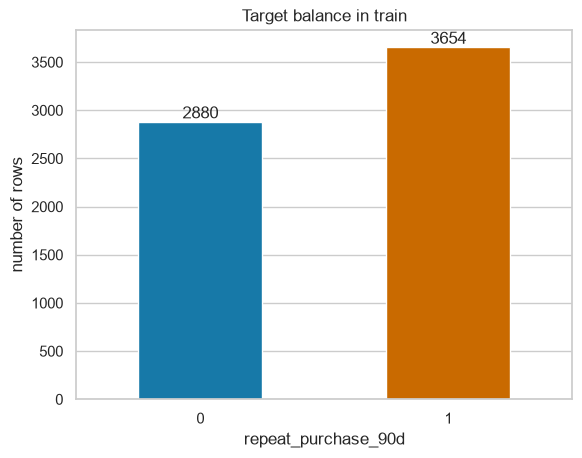

In [67]:
ax = train_raw['repeat_purchase_90d'].value_counts().sort_index().plot(kind='bar', color=['#1779A8', '#C96A00'], rot=0)
ax.bar_label(ax.containers[0])
ax.grid(axis='x', visible=False)
ax.set(xlabel='repeat_purchase_90d', ylabel='number of rows', title='Target balance in train')
plt.show()

In [133]:
purchase_amounts=['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo']
describe_amounts=train_raw[purchase_amounts].describe().T
describe_amounts

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,925.556262,1334.997733,0.93,188.92,476.74,1087.670000,22297.210000
Total Bruto,6469.0,886.152705,1327.641086,0.83,175.74,445.74,1036.700000,21578.280000
Total Liquido,6469.0,773.336384,1136.355723,0.76,154.38,389.91,903.370000,18127.810000
Total Imp_,6469.0,152.219878,225.262375,0.00,29.93,79.74,184.840000,4169.400000
Total Portes,6469.0,1.151427,5.844091,0.00,0.00,0.00,0.000000,181.060000
Total Desc_ Global,6469.0,0.349907,5.116564,0.00,0.00,0.00,0.000000,218.490000
Total Desc_ Linha,6469.0,112.466414,289.986307,0.00,0.00,13.13,92.280000,4103.440000
Custo,6469.0,328.165040,519.507218,0.00,49.05,152.54,396.061499,7427.400583


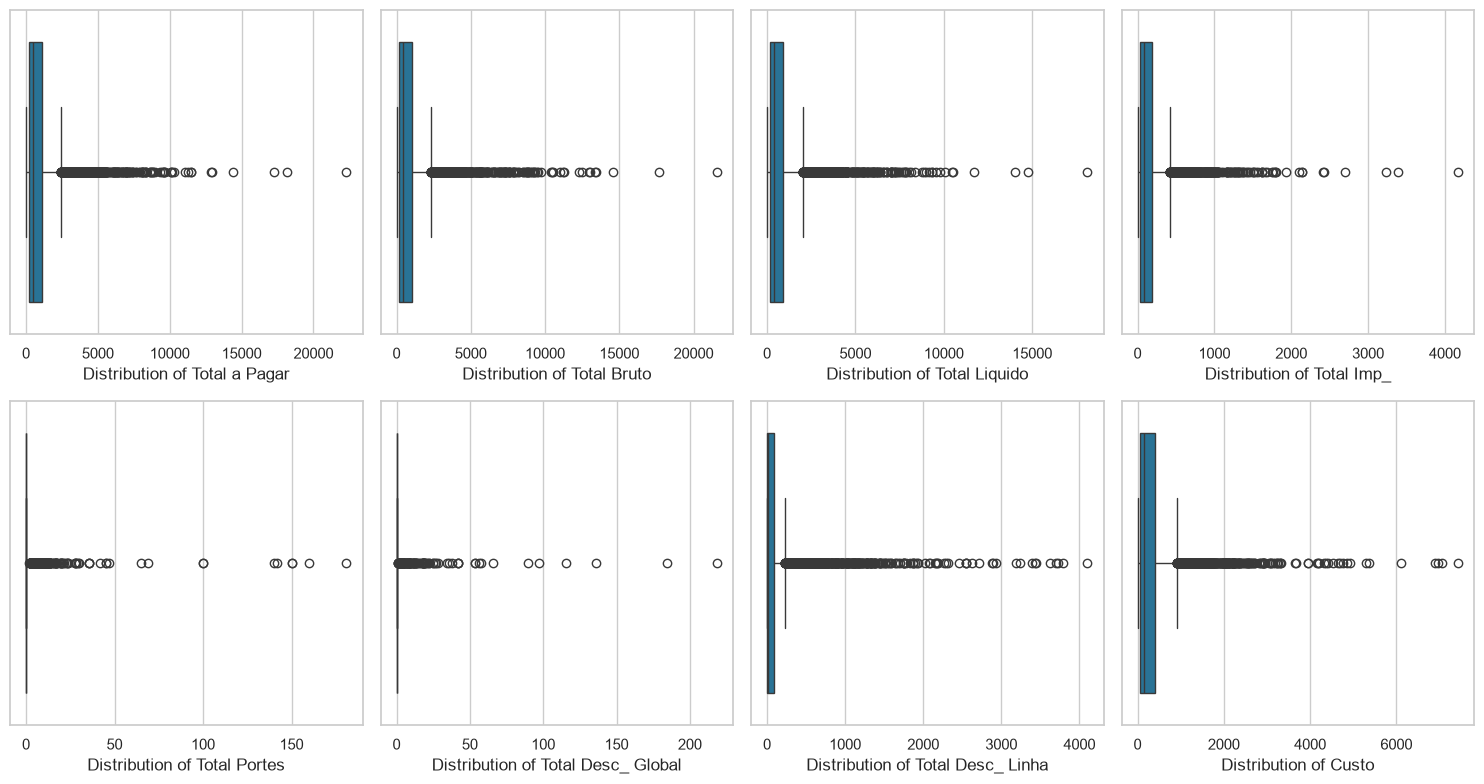

In [143]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()
for i, c in enumerate(purchase_amounts):
    sns.boxplot(x=train_raw[c], ax=axes[i], color='#1779A8')
    axes[i].set_xlabel(f'Distribution of {c}')
plt.tight_layout()
plt.show()

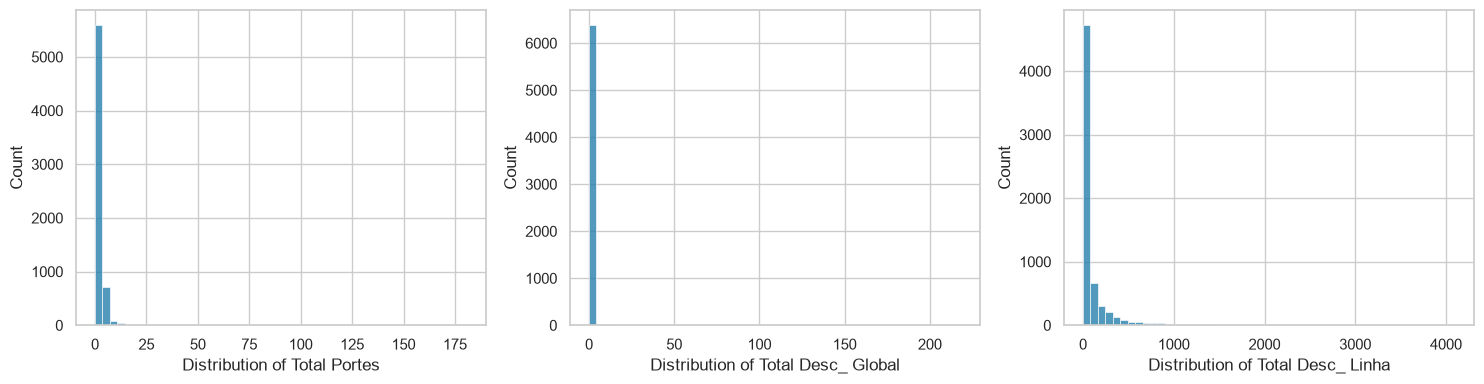

In [144]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha']):
    sns.histplot(data=train_raw, x=c, bins=50, ax=ax, color='#1779A8')
    ax.set_xlabel(f'Distribution of {c}')
plt.tight_layout()
plt.show()

In [134]:
describe_amounts['Skewness'] = train_raw[purchase_amounts].skew()
describe_amounts['IQR']=describe_amounts['75%']-describe_amounts['25%']
describe_amounts['Upper Bound'] = (describe_amounts['75%']+1.5*describe_amounts['IQR'])
describe_amounts['Outlier Count'] = (train_raw[purchase_amounts]>describe_amounts['Upper Bound']).sum()
describe_amounts['Outlier %'] = (describe_amounts['Outlier Count']/describe_amounts['count']*100)
describe_amounts

,count,mean,std,min,25%,50%,75%,max,Skewness,IQR,Upper Bound,Outlier Count,Outlier %
Total a Pagar,6469.0,925.556262,1334.997733,0.93,188.92,476.74,1087.670000,22297.210000,4.208582,898.750000,2435.795000,592,9.151337
Total Bruto,6469.0,886.152705,1327.641086,0.83,175.74,445.74,1036.700000,21578.280000,4.313015,860.960000,2328.140000,584,9.027670
Total Liquido,6469.0,773.336384,1136.355723,0.76,154.38,389.91,903.370000,18127.810000,4.152403,748.990000,2026.855000,587,9.074045
Total Imp_,6469.0,152.219878,225.262375,0.00,29.93,79.74,184.840000,4169.400000,4.836441,154.910000,417.205000,533,8.239295
Total Portes,6469.0,1.151427,5.844091,0.00,0.00,0.00,0.000000,181.060000,19.549332,0.000000,0.000000,1053,16.277632
Total Desc_ Global,6469.0,0.349907,5.116564,0.00,0.00,0.00,0.000000,218.490000,27.457721,0.000000,0.000000,110,1.700417
Total Desc_ Linha,6469.0,112.466414,289.986307,0.00,0.00,13.13,92.280000,4103.440000,5.922600,92.280000,230.700000,822,12.706755
Custo,6469.0,328.165040,519.507218,0.00,49.05,152.54,396.061499,7427.400583,4.611304,347.011499,916.578748,539,8.332045


The boxplots reveal several high-value outliers across the purchase amounts features. However, the maximum values do not appear excessively isolated, as other observations also exhibit relatively high values. This suggests that these outliers may reflect legitimate large purchases instead of data errors. At this point, there is insufficient evidence to justify removing these observations.

These features reveal similar and strongly right-skewed distributions, with most observations concentrated at lower values and a smaller number of high-value outliers (2-16%). The similarity between these distributions may suggest redundancy among some features, which should be further investigated through correlation analysis.

In [ ]:
clients_raw = pd.read_csv('../data/clientes.csv', index_col='customer_id')

print(f'Clients dataset dimensions: {clients_raw.shape[0]} rows x {clients_raw.shape[1]} feature columns, indexed by customer_id')
clients_raw.head()

|Group|Features|Info|Type of variable|
|---|---|---|---|
|Identifier|`customer_id`|It is the join key between `train`/`test` datasets and the `clientes` dataset|Identifier
|Tenure|`customer_since_year`|Self-explanatory from the column name|Time (year)|
|Type|`customer_type` |Empty column|---|
|Geography|`country_or_region`, `commercial_region`, `island`, `municipality`, `city`, `postal_area`, `postal_code`, `street`, `address`|Nominal Categorical|Self-explanatory from the columns names|
| Name |`company_name`|Self-explanatory from the column name|Nominal Categorical|